## Optimization

`fsolve` solves systems of nonlinear equations $F(x) = 0$ from a starting point. Where does the circle $x^2 + y^2 = 4$ meet the parabola $y = x^2 - 1$? Two starting points find the two crossings on the right and left:

In [ ]:
F = @(v) [v(1)^2 + v(2)^2 - 4; v(2) - v(1)^2 + 1];
opts = optimoptions('fsolve', 'Display', 'off');
for x0 = [1 -1]
    v = fsolve(F, [x0; 1], opts);
    fprintf('from (%g, 1): x = %8.5f, y = %8.5f, residual %.1e\n', x0, v, norm(F(v)))
end

from (1, 1): x =  1.51749, y =  1.30278, residual 2.2e-16


from (-1, 1): x = -1.51749, y =  1.30278, residual 2.2e-16


`fminunc` minimizes a smooth function of several variables, here Rosenbrock's banana-shaped valley, with its minimum at $(1, 1)$. It prints MATLAB's exit message by default:

In [ ]:
rosen = @(x) 100*(x(2) - x(1)^2)^2 + (1 - x(1))^2;
[x, fval] = fminunc(rosen, [-1.2; 1]);
fprintf('x = (%.4f, %.4f), f = %.1e\n', x, fval)


Local minimum found.

Optimization completed because the size of the gradient is less than
the value of the optimality tolerance.

<stopping criteria details>
x = (1.0000, 1.0000), f = 1.5e-11


`lsqcurvefit` fits a model's coefficients to data by least squares. Noisy measurements of a decay $c_1 e^{-c_2 t} + c_3$:

c = [3.961 0.783 0.960]


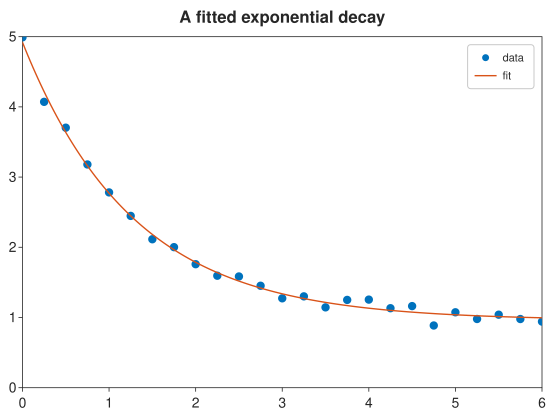

In [ ]:
rng(2);
t = (0:0.25:6)'; y = 4*exp(-0.8*t) + 1 + 0.08*randn(size(t));
model = @(c, t) c(1)*exp(-c(2)*t) + c(3);
c = lsqcurvefit(model, [1 1 0], t, y, [], [], optimoptions('lsqcurvefit', 'Display', 'off'));
fprintf('c = [%.3f %.3f %.3f]\n', c)
tt = linspace(0, 6, 200);
plot(t, y, 'o', tt, model(c, tt)), legend('data', 'fit'), title('A fitted exponential decay')

`linprog` solves linear programs. A workshop makes chairs (\$40 profit each) and tables (\$70), limited by 60 hours of carpentry (2 and 4 hours each) and 40 of finishing (2 and 2): maximize profit, that is, minimize its negative. `lambda.ineqlin` holds what one more hour of each is worth:

In [ ]:
f = -[40; 70]; A = [2 4; 2 2]; b = [60; 40];
[x, fval, ~, ~, lambda] = linprog(f, A, b, [], [], [0; 0], [], optimoptions('linprog', 'Display', 'off'));
fprintf('%g chairs and %g tables earn $%g\n', x, -fval)
fprintf('an hour of carpentry is worth $%g, of finishing $%g\n', lambda.ineqlin)

10 chairs and 10 tables earn $1100


an hour of carpentry is worth $15, of finishing $5
